Carregamento de Dados e contagem de valores nulos existentes em cada coluna.


In [ ]:
import pandas as pd

caminho_arquivo = 'data.csv'
df = pd.read_csv(caminho_arquivo, sep=";")
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance\t                      0
Previous qualification                            0
Previous qualification (grade)                    0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Admission grade                                   0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrol

In [33]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.describe ()


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,18.669078,1.727848,8856.642631,0.890823,4.577758,132.613314,1.873192,19.561935,22.275316,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,17.484682,1.313793,2063.566416,0.311897,10.216592,13.188332,6.914514,15.603186,15.343108,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder


variaveis_numericas = df.select_dtypes(include=['float64', 'int64'])
variaveis_categoricas = df.select_dtypes(include=['object'])


scaler = StandardScaler()
variaveis_numericas_normalizadas = pd.DataFrame(scaler.fit_transform(variaveis_numericas), columns=variaveis_numericas.columns)

encoder = LabelEncoder()
variaveis_categoricas_codificadas = variaveis_categoricas.apply(encoder.fit_transform)


df_normalizado = pd.concat([variaveis_categoricas_codificadas, variaveis_numericas_normalizadas], axis=1)


print(df_normalizado.head())


   Target  Marital status  Application mode  Application order    Course  \
0       0       -0.294829         -0.095470           2.490896 -4.209520   
1       2       -0.294829         -0.209869          -0.554068  0.192580   
2       0       -0.294829         -1.010660           2.490896  0.103404   
3       2       -0.294829         -0.095470           0.207173  0.444115   
4       2        1.356212          1.162916          -0.554068 -0.408389   

   Daytime/evening attendance\t  Previous qualification  \
0                      0.350082                -0.35023   
1                      0.350082                -0.35023   
2                      0.350082                -0.35023   
3                      0.350082                -0.35023   
4                     -2.856470                -0.35023   

   Previous qualification (grade)  Nacionality  Mother's qualification  ...  \
0                       -0.804841    -0.126298               -0.036018  ...   
1                        2.076

/usr/local/lib/python3.10/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.draw()
/usr/local/lib/python3.10/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


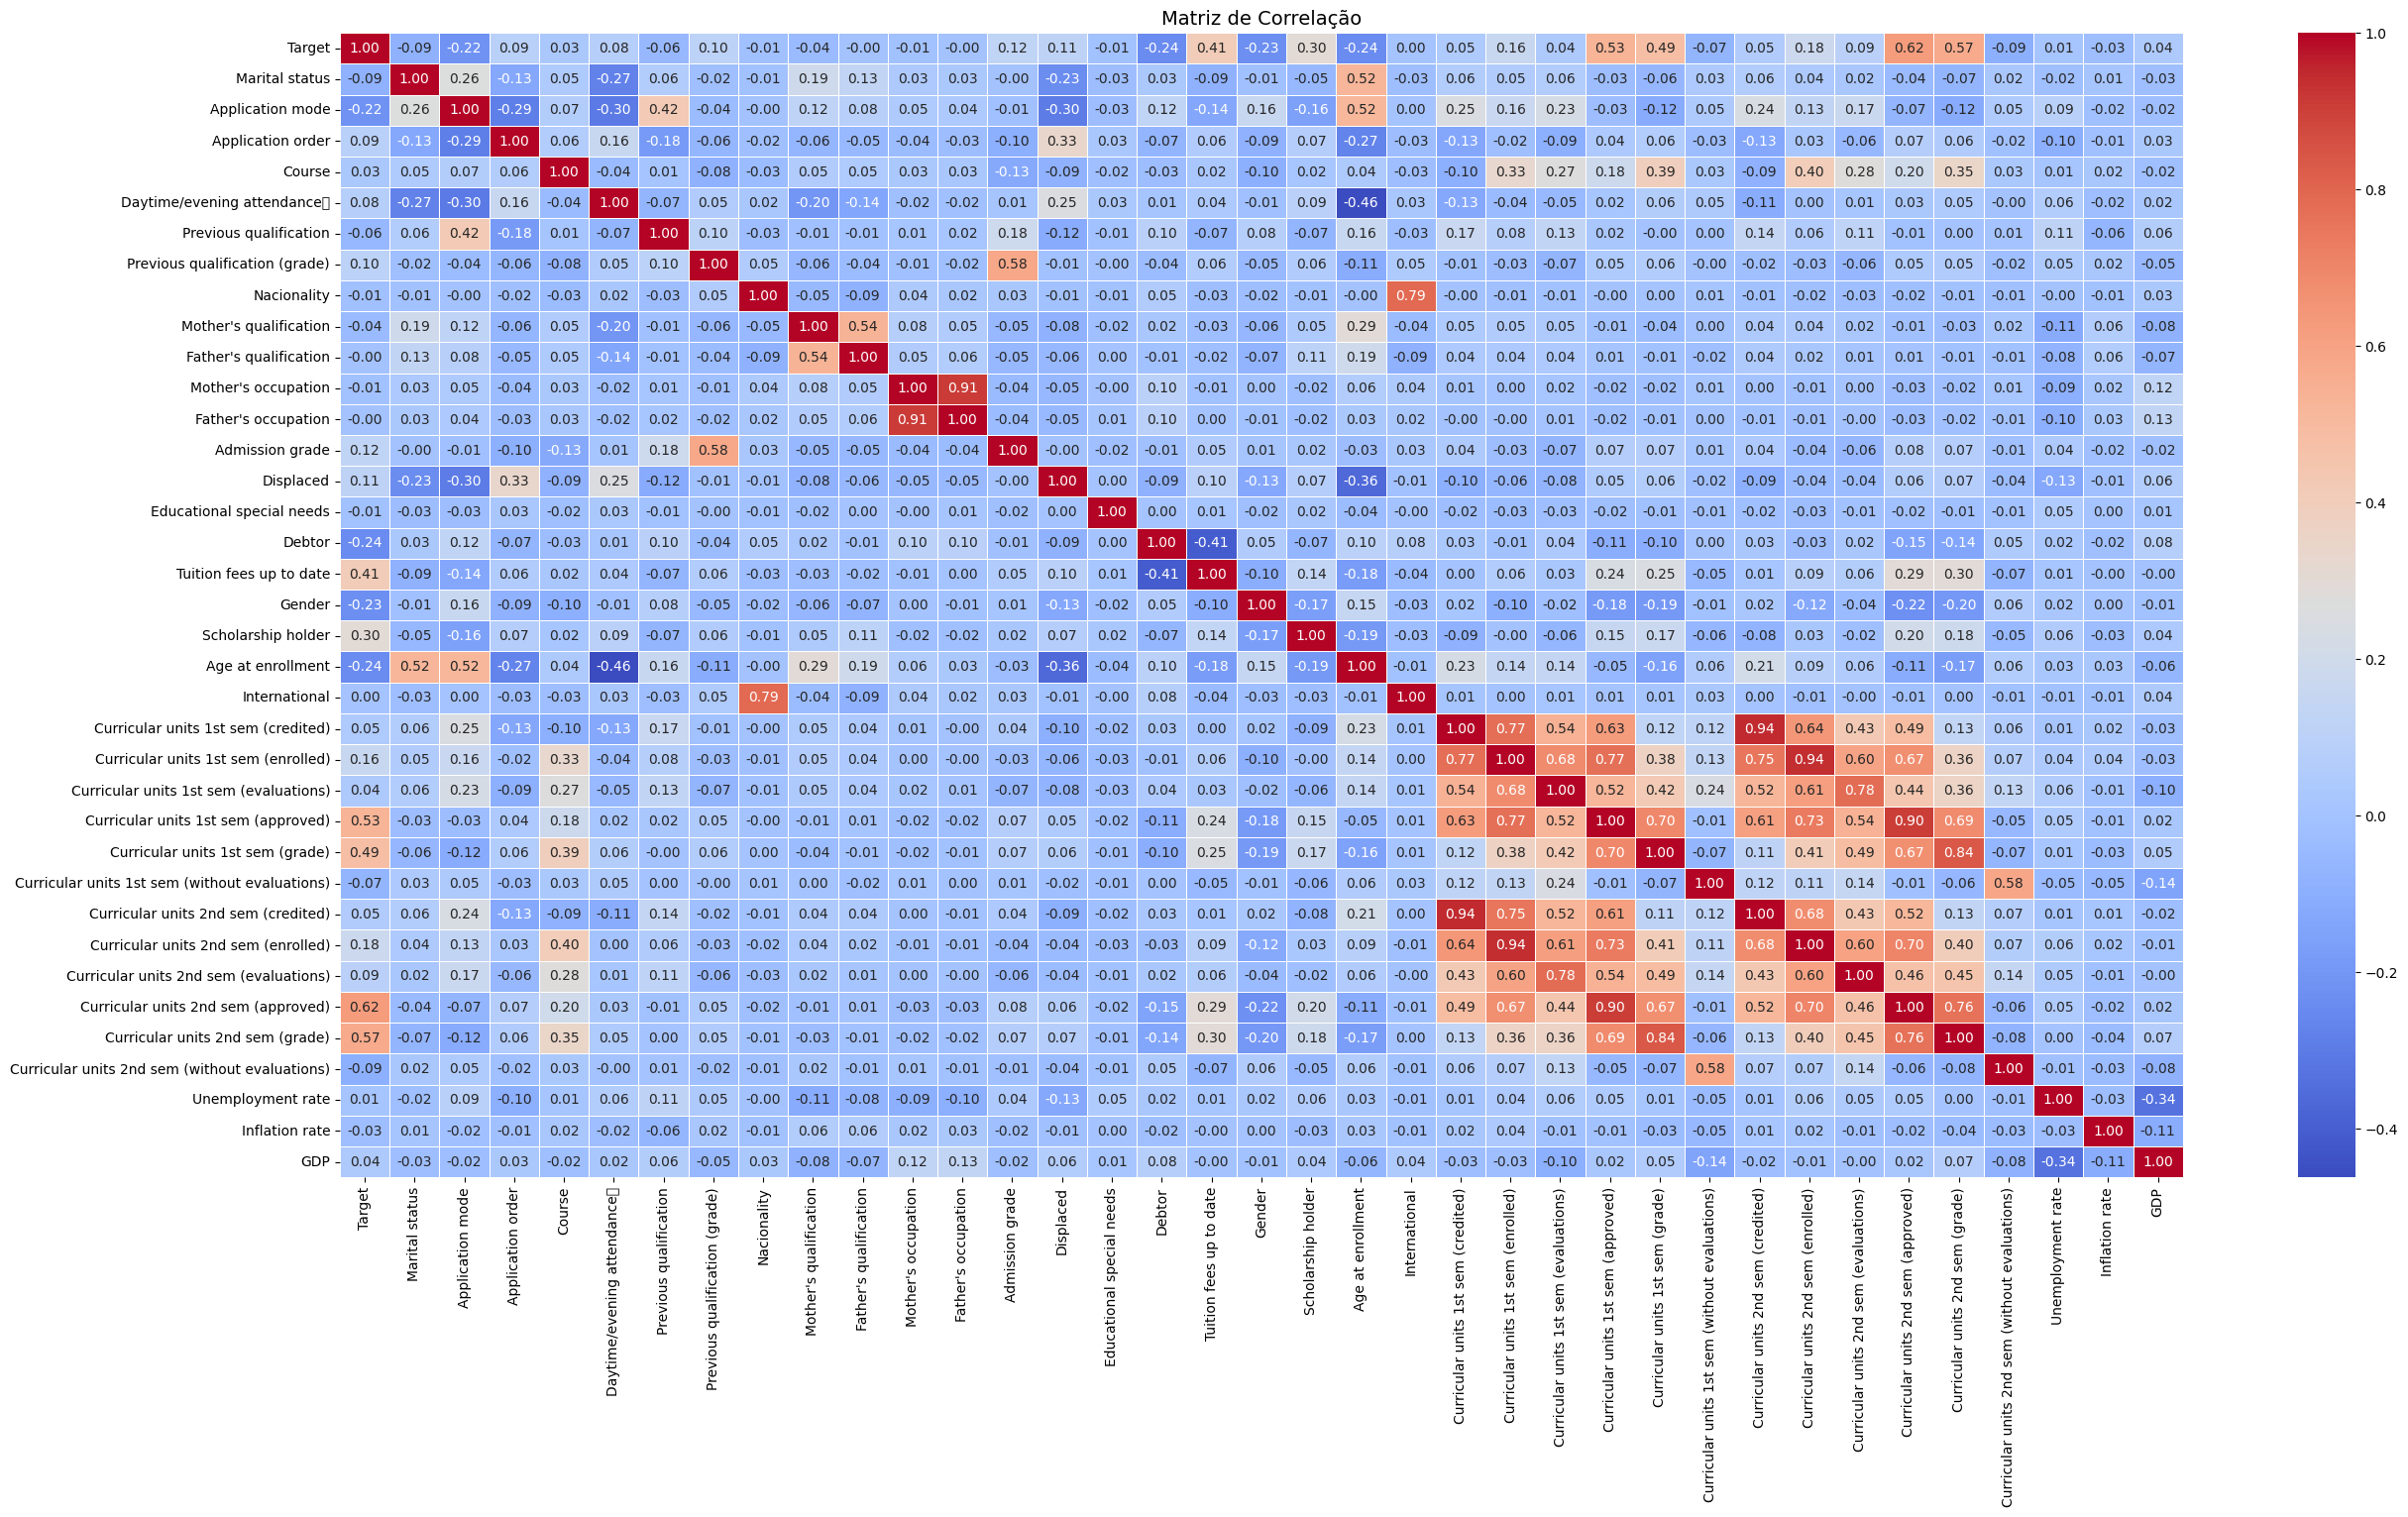

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = df_normalizado.corr()

plt.figure(figsize=(30, 15))

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, cbar=True)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.title('Matriz de Correlação', fontsize=14)

plt.show()


Remover variaveis

In [ ]:
variaveis_irrelevantes = [
    "Application mode",
    "Previous qualification",
    "International",
    "Mother's occupation",
    "Father's occupation",
    "Previous qualification (grade)",
    "Debtor",
    "Curricular units 1st sem (credited)",
    "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)",
    "Curricular units 2nd sem (credited)",
    "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)",
]

df = df.drop(variaveis_irrelevantes, axis=1)

print(df.head())


   Marital status  Application order  Course  Daytime/evening attendance\t  \
0               1                  5     171                             1   
1               1                  1    9254                             1   
2               1                  5    9070                             1   
3               1                  2    9773                             1   
4               2                  1    8014                             0   

   Nacionality  Mother's qualification  Father's qualification  \
0            1                      19                      12   
1            1                       1                       3   
2            1                      37                      37   
3            1                      38                      37   
4            1                      37                      38   

   Admission grade  Displaced  Educational special needs  ...  \
0            127.3          1                          0  ...   
1   

Modelos
---
K-Nearest Neighbors

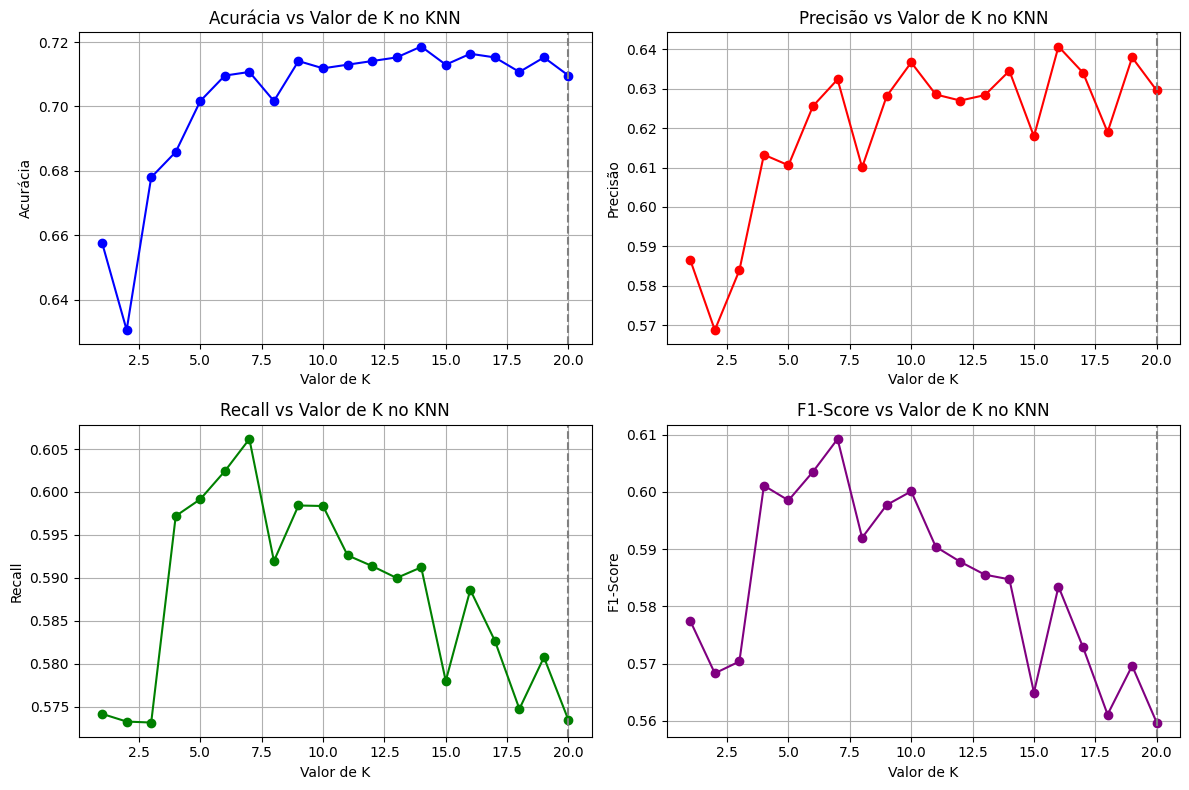

Resultados para k = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20]
Acurácia: [0.6576271186440678, 0.6305084745762712, 0.6779661016949152, 0.6858757062146893, 0.7016949152542373, 0.7096045197740113, 0.7107344632768362, 0.7016949152542373, 0.7141242937853107, 0.711864406779661, 0.7129943502824859, 0.7141242937853107, 0.7152542372881356, 0.7186440677966102, 0.7129943502824859, 0.7163841807909604, 0.7152542372881356, 0.7107344632768362, 0.7152542372881356, 0.7096045197740113]
Precisão: [0.5865178854521437, 0.5687421167297328, 0.5839065480066387, 0.6132704596990312, 0.6105802624218796, 0.625623686107557, 0.6323936879426221, 0.6100402359174288, 0.6281225334165167, 0.6366972394791134, 0.6285617575299697, 0.6270149151614669, 0.6283984645578388, 0.63456125869042, 0.6179104896054207, 0.6407414662435815, 0.6340743951856517, 0.6190075356742023, 0.6379644104040636, 0.6295873015873016]
Recall: [0.574180227430158, 0.5732831734492878, 0.5731693621069799, 0.597205281434559, 0.5

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Construção de um gráfico

X = df.drop(columns=['Target'])
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

k_values = list(range(1, 21))

accuracy_scores = []
precision_scores = []
recall_scores = []
f1_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)

    y_pred = knn.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    f1 = f1_score(y_test, y_pred, average='macro')

    accuracy_scores.append(accuracy)
    precision_scores.append(precision)
    recall_scores.append(recall)
    f1_scores.append(f1)

plt.figure(figsize=(12, 8))

# Gráfico de Acurácia
plt.subplot(2, 2, 1)
plt.plot(k_values, accuracy_scores, marker='o', linestyle='-', color='b')
plt.title('Acurácia vs Valor de K no KNN')
plt.xlabel('Valor de K')
plt.ylabel('Acurácia')
plt.grid(True)
plt.axvline(x=k, color='gray', linestyle='--')


# Gráfico de Precisão
plt.subplot(2, 2, 2)
plt.plot(k_values, precision_scores, marker='o', linestyle='-', color='r')
plt.title('Precisão vs Valor de K no KNN')
plt.xlabel('Valor de K')
plt.ylabel('Precisão')
plt.grid(True)
plt.axvline(x=k, color='gray', linestyle='--')


# Gráfico de Recall
plt.subplot(2, 2, 3)
plt.plot(k_values, recall_scores, marker='o', linestyle='-', color='g')
plt.title('Recall vs Valor de K no KNN')
plt.xlabel('Valor de K')
plt.ylabel('Recall')
plt.grid(True)
plt.axvline(x=k, color='gray', linestyle='--')


# Gráfico de F1-score
plt.subplot(2, 2, 4)
plt.plot(k_values, f1_scores, marker='o', linestyle='-', color='purple')
plt.title('F1-Score vs Valor de K no KNN')
plt.xlabel('Valor de K')
plt.ylabel('F1-Score')
plt.grid(True)
plt.axvline(x=k, color='gray', linestyle='--')


plt.tight_layout()
plt.show()


print("Resultados para k =", k_values)
print("Acurácia:", accuracy_scores)
print("Precisão:", precision_scores)
print("Recall:", recall_scores)
print("F1-Score:", f1_scores)


Decision Trees

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning

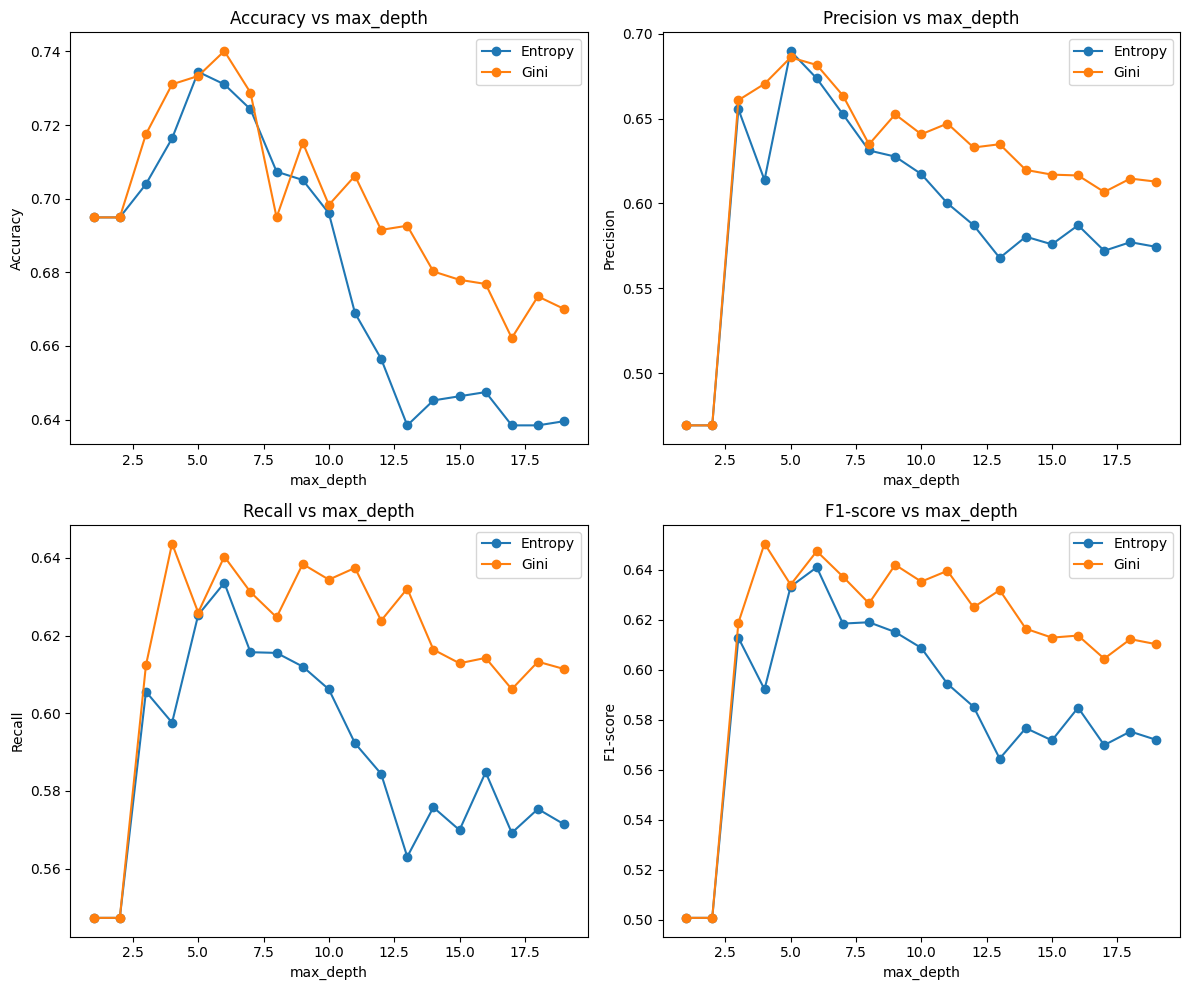

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X = df.drop(columns=['Target'])
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

max_depth_range = range(1, 20)

# métricas de avaliação
accuracy_results_entropy = []
precision_results_entropy = []
recall_results_entropy = []
f1_results_entropy = []

accuracy_results_gini = []
precision_results_gini = []
recall_results_gini = []
f1_results_gini = []

# Avaliar o desempenho do modelo para cada valor de max_depth
for depth in max_depth_range:
    #entropia
    tree_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=42)
    tree_entropy.fit(X_train, y_train)
    y_pred_entropy = tree_entropy.predict(X_test)
    accuracy_entropy = accuracy_score(y_test, y_pred_entropy)
    precision_entropy = precision_score(y_test, y_pred_entropy, average='macro')
    recall_entropy = recall_score(y_test, y_pred_entropy, average='macro')
    f1_entropy = f1_score(y_test, y_pred_entropy, average='macro')
    accuracy_results_entropy.append(accuracy_entropy)
    precision_results_entropy.append(precision_entropy)
    recall_results_entropy.append(recall_entropy)
    f1_results_entropy.append(f1_entropy)

    # Gini
    tree_gini = DecisionTreeClassifier(criterion='gini', max_depth=depth, random_state=42)
    tree_gini.fit(X_train, y_train)
    y_pred_gini = tree_gini.predict(X_test)
    accuracy_gini = accuracy_score(y_test, y_pred_gini)
    precision_gini = precision_score(y_test, y_pred_gini, average='macro')
    recall_gini = recall_score(y_test, y_pred_gini, average='macro')
    f1_gini = f1_score(y_test, y_pred_gini, average='macro')
    accuracy_results_gini.append(accuracy_gini)
    precision_results_gini.append(precision_gini)
    recall_results_gini.append(recall_gini)
    f1_results_gini.append(f1_gini)

# Plots
plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.plot(max_depth_range, accuracy_results_entropy, marker='o', label='Entropy')
plt.plot(max_depth_range, accuracy_results_gini, marker='o', label='Gini')
plt.title('Accuracy vs max_depth')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(2, 2, 2)
plt.plot(max_depth_range, precision_results_entropy, marker='o', label='Entropy')
plt.plot(max_depth_range, precision_results_gini, marker='o', label='Gini')
plt.title('Precision vs max_depth')
plt.xlabel('max_depth')
plt.ylabel('Precision')
plt.legend()

plt.subplot(2, 2, 3)
plt.plot(max_depth_range, recall_results_entropy, marker='o', label='Entropy')
plt.plot(max_depth_range, recall_results_gini, marker='o', label='Gini')
plt.title('Recall vs max_depth')
plt.xlabel('max_depth')
plt.ylabel('Recall')
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(max_depth_range, f1_results_entropy, marker='o', label='Entropy')
plt.plot(max_depth_range, f1_results_gini, marker='o', label='Gini')
plt.title('F1-score vs max_depth')
plt.xlabel('max_depth')
plt.ylabel('F1-score')
plt.legend()

plt.tight_layout()
plt.show()





In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

X = df.drop(columns=['Target'])
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

params1 = {'criterion': 'gini', 'max_depth': 7, 'min_samples_split': 23, 'min_samples_leaf': 38}
params2 = {'criterion': 'entropy', 'max_depth': 7,'min_samples_split': 23,'min_samples_leaf': 17}

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# tree 1
tree1.fit(X_train, y_train)
y_pred1 = tree1.predict(X_test)
accuracy1 = accuracy_score(y_test, y_pred1)
precision1 = precision_score(y_test, y_pred1, average='macro')
recall1 = recall_score(y_test, y_pred1, average='macro')
f1_1 = f1_score(y_test, y_pred1, average='macro')

print("Metrics for Decision Tree 1:")
print("Accuracy:", accuracy1)
print("Precision:", precision1)
print("Recall:", recall1)
print("F1-score:", f1_1)
print()

# Tree 2
tree2.fit(X_train, y_train)
y_pred2 = tree2.predict(X_test)
accuracy2 = accuracy_score(y_test, y_pred2)
precision2 = precision_score(y_test, y_pred2, average='macro')
recall2 = recall_score(y_test, y_pred2, average='macro')
f1_2 = f1_score(y_test, y_pred2, average='macro')

print("Metrics for Decision Tree 2:")
print("Accuracy:", accuracy2)
print("Precision:", precision2)
print("Recall:", recall2)
print("F1-score:", f1_2)
print()



Metrics for Decision Tree 1:
Accuracy: 0.7423728813559322
Precision: 0.6887497564819419
Recall: 0.6478433402415648
F1-score: 0.6563867016622922

Metrics for Decision Tree 2:
Accuracy: 0.7423728813559322
Precision: 0.694263962784508
Recall: 0.646310246309805
F1-score: 0.6556866317221569



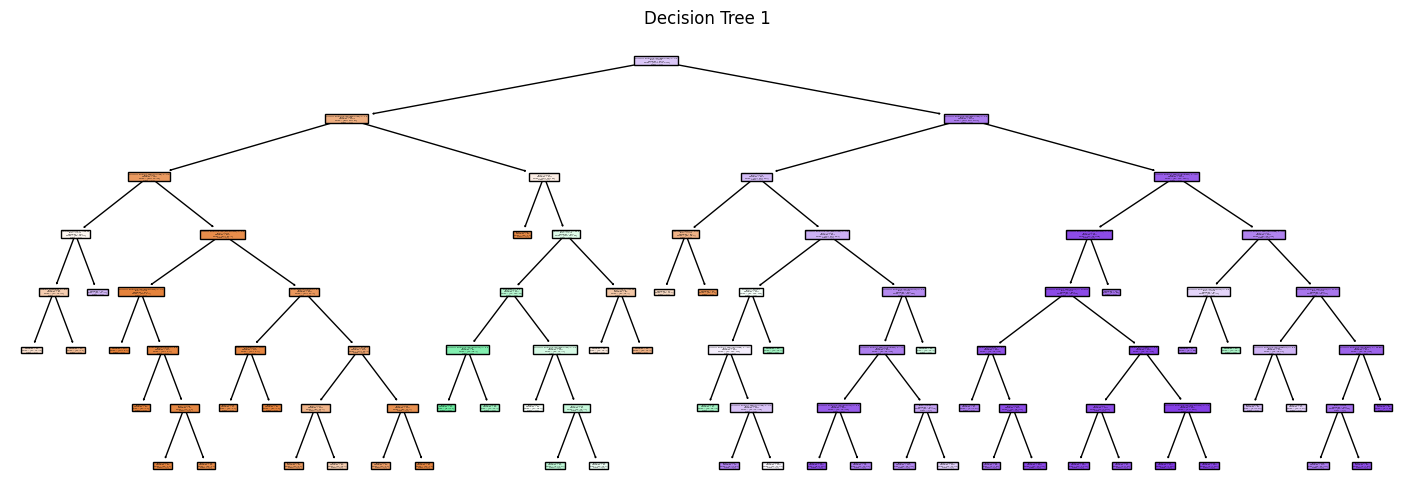

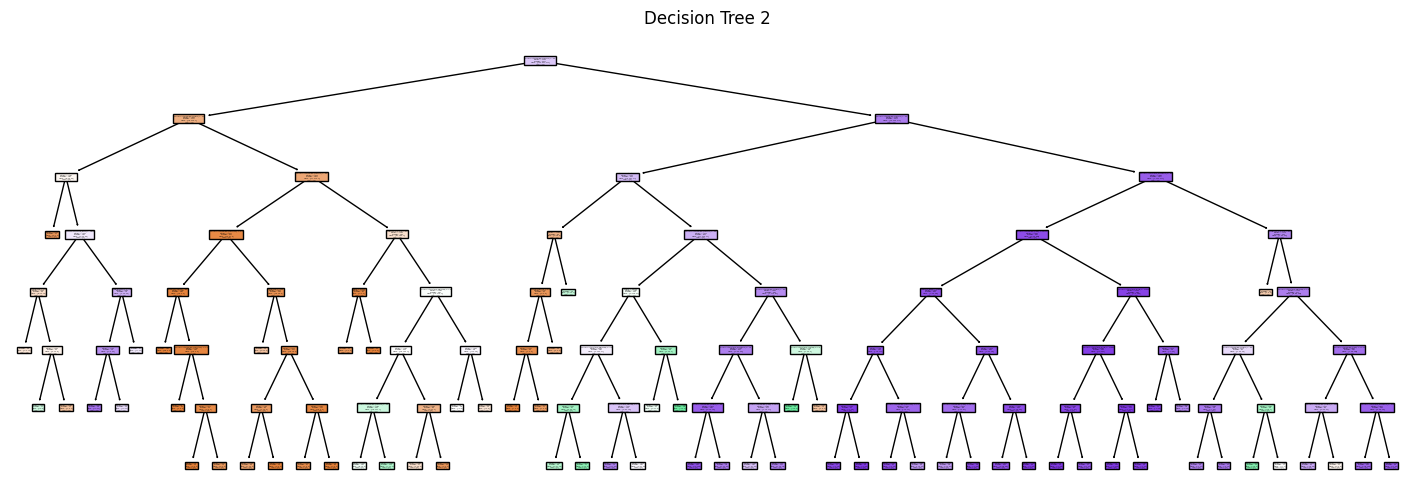

In [ ]:
# Tree 1
tree1 = DecisionTreeClassifier(**params1, random_state=42)
tree1.fit(X_train, y_train)

plt.figure(figsize=(18, 6))
plot_tree(tree1, filled=True, feature_names=X.columns, class_names=True)
plt.title("Decision Tree 1")
plt.show()

# Tree 2
tree2 = DecisionTreeClassifier(**params2, random_state=42)
tree2.fit(X_train, y_train)

plt.figure(figsize=(18, 6))
plot_tree(tree2, filled=True, feature_names=X.columns, class_names=True)
plt.title("Decision Tree 2")
plt.show()